# CSET485 Assignment 1 · COMPAS audit

**Roll 0352 · seed 352 · 70/30 holdout**

This notebook reproduces every data-derived quantity and both figures in the accompanying report. Install the packages in `requirements.txt`, then run the cells in order with Python 3.13. The first cell downloads the pinned ProPublica source and verifies its SHA-256 digest. A byte-identical `.compas-source.csv` in the working directory can also be used for offline execution. Identify the course’s `is_recidivist` target with the raw `is_recid` column. Individual rows and identifiers are excluded from saved outputs.


## Source and cohort

Check the two targets and the assessment-time feature roster. Keep valid ages and history counts at their observed values, including valid extremes. Code age in decades and keep all count predictors in their natural units. Dummy-code categorical predictors with Male, Caucasian and felony as references. Stratify the split by `is_recid`; the same row indices are used for both models.

In [1]:
%matplotlib inline

from hashlib import sha256
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import norm
from sklearn.metrics import accuracy_score, confusion_matrix, mean_absolute_error, roc_auc_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.multitest import multipletests

ROLL = '0352'
SEED = int(ROLL[-3:])
DATA_COMMIT = 'c062fbb5fa84f6c99d82f432c46b405f3a0ca5ec'
DATA_URL = ('https://raw.githubusercontent.com/propublica/compas-analysis/'
            f'{DATA_COMMIT}/compas-scores-two-years.csv')
DATA_HASH = 'c451db85908b2f7fef1d83203bedf6b71ecda0d5af468d82ae62178f91d0cc7d'
cache = Path('.compas-source.csv')
if cache.exists():
    raw_bytes = cache.read_bytes()
else:
    with urlopen(DATA_URL, timeout=60) as response:
        raw_bytes = response.read()
if sha256(raw_bytes).hexdigest() != DATA_HASH:
    raise ValueError('COMPAS source contents differ from the snapshot used in the report.')

counts = ['priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count']
category_levels = {
    'sex': ['Male', 'Female'],
    'race': ['Caucasian', 'African-American', 'Asian', 'Hispanic', 'Native American', 'Other'],
    'c_charge_degree': ['F', 'M'],
}
fields = ['id', 'age', *counts, *category_levels, 'decile_score', 'is_recid']
raw = pd.read_csv(BytesIO(raw_bytes), usecols=fields)
assert raw['id'].is_unique
missing = raw.drop(columns='id').isna().sum()
valid = raw['is_recid'].isin([0, 1]) & raw['decile_score'].between(1, 10)
valid &= raw['age'].ge(18) & raw[counts].ge(0).all(axis=1)
for feature, levels in category_levels.items():
    valid &= raw[feature].isin(levels)
data = raw.loc[valid].drop(columns='id').copy()
data['age_10'] = data['age'] / 10
features = ['age_10', *counts, *category_levels]
X = pd.get_dummies(
    data[features].astype({name: pd.CategoricalDtype(levels, ordered=True)
                           for name, levels in category_levels.items()}),
    drop_first=True, dtype=float,
)
X = sm.add_constant(X, has_constant='add').astype(float)
train, test = train_test_split(data.index.to_numpy(), test_size=0.30, random_state=SEED,
                               stratify=data['is_recid'])
assert len(set(train) & set(test)) == 0
assert len(train) + len(test) == len(data)
target = data['is_recid']
ranges = data[['age', *counts]].agg(['min', 'max']).T
print(f'Source: {len(raw):,}; retained: {len(data):,}; train: {len(train):,}; test: {len(test):,}')
print('Missing cells in selected input/target columns:', int(missing.sum()))
print(ranges.to_string())

Source: 7,214; retained: 7,214; train: 5,049; test: 2,165
Missing cells in selected input/target columns: 0
                 min  max
age               18   96
priors_count       0   38
juv_fel_count      0   20
juv_misd_count     0   13
juv_other_count    0   17


## Part 1 - Holdout comparison

Fit OLS to the 1–10 COMPAS decile and maximum-likelihood logistic regression to the binary recorded recidivism label. The agreement matrix uses OLS flags as rows and logistic flags as columns. Accuracy and AUROC compare logistic predictions with the observed label. MAE compares OLS predictions with the recorded decile.

In [2]:
def fit_logit(design, outcome):
    model = sm.Logit(outcome, design).fit(method='newton', disp=False, maxiter=100)
    if not model.mle_retvals['converged']:
        raise RuntimeError('Logistic regression failed to converge.')
    return model


linear = sm.OLS(data.loc[train, 'decile_score'], X.loc[train]).fit()
logistic = fit_logit(X.loc[train], target.loc[train])
score = linear.predict(X.loc[test])
probability = logistic.predict(X.loc[test])
median_score = float(score.median())
linear_flag = score.ge(median_score)
logistic_flag = probability.ge(0.50)
agreement = confusion_matrix(linear_flag, logistic_flag, labels=[False, True])
only_logit, only_linear = int(agreement[0, 1]), int(agreement[1, 0])
mismatch = only_logit + only_linear
mismatch_pct = 100 * mismatch / len(test)
accuracy50 = accuracy_score(target.loc[test], logistic_flag)
mae = mean_absolute_error(data.loc[test, 'decile_score'], score)
auc = roc_auc_score(target.loc[test], probability)
print(pd.DataFrame(agreement, index=['OLS low', 'OLS high'], columns=['Logit low', 'Logit high']))
print(f'Median {median_score:.4f}; mismatches {mismatch} ({mismatch_pct:.2f}%); '
      f'logit accuracy {accuracy50:.2%}; AUROC {auc:.4f}; OLS MAE {mae:.4f}')

          Logit low  Logit high
OLS low        1038          44
OLS high        167         916
Median 4.5836; mismatches 211 (9.75%); logit accuracy 67.85%; AUROC 0.7377; OLS MAE 1.7799


## Part 2.1 - Full-cohort exploratory subgroup coefficients

Fit a pooled logistic regression and two recorded-sex strata on the full cohort for the exploratory subgroup exercise. A strict sign reversal requires both stratum slopes to oppose the pooled slope. Use 95% pointwise Wald intervals for slopes and the difference of independent stratum estimates. Holm-adjust the difference tests across all shared predictors. Holdout predictions remain those from Part 1.

In [3]:
sex_column = 'sex_Female'
female = data['sex'].eq('Female')
male = data['sex'].eq('Male')
pooled = fit_logit(X, target)
female_logit = fit_logit(X.loc[female].drop(columns=sex_column), target.loc[female])
male_logit = fit_logit(X.loc[male].drop(columns=sex_column), target.loc[male])
shared_predictors = female_logit.params.index.drop('const')
subgroup = pd.DataFrame(index=shared_predictors)
for label, model in [('Pooled', pooled), ('Female', female_logit), ('Male', male_logit)]:
    subgroup[label] = model.params.loc[shared_predictors]
    subgroup[[f'{label} lower', f'{label} upper']] = model.conf_int().loc[shared_predictors].to_numpy()
subgroup['Female minus male'] = subgroup['Female'] - subgroup['Male']
subgroup_se = np.hypot(female_logit.bse.loc[shared_predictors], male_logit.bse.loc[shared_predictors])
subgroup['Difference lower'] = subgroup['Female minus male'] - norm.ppf(.975) * subgroup_se
subgroup['Difference upper'] = subgroup['Female minus male'] + norm.ppf(.975) * subgroup_se
subgroup['p'] = 2 * norm.sf(np.abs(subgroup['Female minus male'] / subgroup_se))
subgroup['Holm p'] = multipletests(subgroup['p'], method='holm')[1]
subgroup['Both slopes reversed'] = (
    np.sign(subgroup['Pooled']).ne(np.sign(subgroup['Female']))
    & np.sign(subgroup['Pooled']).ne(np.sign(subgroup['Male']))
)
print(subgroup.round(5).to_string())

                        Pooled  Pooled lower  Pooled upper   Female  Female lower  Female upper     Male  Male lower  Male upper  Female minus male  Difference lower  Difference upper        p   Holm p  Both slopes reversed
age_10                -0.44454      -0.49371      -0.39536 -0.41350      -0.53132      -0.29569 -0.45296    -0.50717    -0.39876            0.03946          -0.09022           0.16915  0.55092  1.00000                 False
priors_count           0.15166       0.13716       0.16616  0.21304       0.16846       0.25761  0.14276     0.12746     0.15807            0.07027           0.02314           0.11740  0.00348  0.03823                 False
juv_fel_count          0.19759       0.01960       0.37558  0.39485      -0.54492       1.33462  0.20028     0.01969     0.38087            0.19457          -0.76240           1.15153  0.69027  1.00000                 False
juv_misd_count         0.04865      -0.10360       0.20090  0.15454      -0.31791       0.62699  0.03569

## Part 2.2 - Omit prior count, same training rows

Drop prior count and refit on the same training rows with the same feature units. The signed relative shift equals `100 × (reduced − full) / abs(full)`. Rank by absolute relative shift and separately by absolute log-odds shift. Logistic coefficient shifts can include non-collapsibility and should be interpreted as a sensitivity analysis.

In [4]:
reduced = fit_logit(X.loc[train].drop(columns='priors_count'), target.loc[train])
shift = pd.DataFrame({'Full': logistic.params, 'Reduced': reduced.params}).dropna().drop(index='const')
shift['Difference'] = shift['Reduced'] - shift['Full']
shift['Relative shift (%)'] = 100 * shift['Difference'] / shift['Full'].abs()
shift['Absolute relative shift (%)'] = shift['Relative shift (%)'].abs()
most_shift = shift['Absolute relative shift (%)'].idxmax()
largest_raw_shift = shift['Difference'].abs().idxmax()
train_data = data.loc[train]
history_correlations = train_data[['age_10', *counts]].corr()['priors_count'].drop('priors_count')
print(shift.round(5).to_string())
print('Pearson correlations with omitted prior count:')
print(history_correlations.round(4).to_string())

                          Full  Reduced  Difference  Relative shift (%)  Absolute relative shift (%)
age_10                -0.44309 -0.27906     0.16402            37.01843                     37.01843
c_charge_degree_M     -0.13168 -0.29684    -0.16516          -125.42675                    125.42675
juv_fel_count          0.22542  0.51214     0.28672           127.19332                    127.19332
juv_misd_count         0.03729  0.34224     0.30495           817.88306                    817.88306
juv_other_count        0.13737  0.24063     0.10326            75.16790                     75.16790
race_African-American  0.09261  0.31952     0.22691           245.00386                    245.00386
race_Asian            -0.49633 -0.68029    -0.18396           -37.06438                     37.06438
race_Hispanic         -0.27593 -0.28269    -0.00676            -2.45008                      2.45008
race_Native American  -0.22463  0.20100     0.42564           189.47940                    

## Part 2.3 - High-confidence errors and score contributions

Find both tails of confident test mistakes and sample 50 without replacement using seed 352. Display aggregated profiles and score contributions. The tail summary reports observed prevalence and mean predicted probability across all test rows in each tail, including correctly classified cases.

In [5]:
holdout = data.loc[test, ['age', 'sex', 'race', 'c_charge_degree', *counts]].copy()
holdout['actual'] = target.loc[test]
holdout['probability'] = probability
confident_fp = probability.ge(.75) & holdout['actual'].eq(0)
confident_fn = probability.le(.25) & holdout['actual'].eq(1)
errors = holdout.loc[confident_fp | confident_fn].copy()
errors['error'] = np.where(errors['actual'].eq(1), 'False negative', 'False positive')
subset = errors.sample(n=50, random_state=SEED) if len(errors) > 50 else errors.copy()
error_pct = 100 * len(errors) / len(holdout)


def population_profile(frame):
    groups = {'Age <25': frame['age'].lt(25),
              'Age 25-45': frame['age'].between(25, 45),
              'Age >45': frame['age'].gt(45)}
    for feature in ('sex', 'race'):
        groups.update({level: frame[feature].eq(level) for level in category_levels[feature]})
    groups.update({'Priors = 0': frame['priors_count'].eq(0),
                   'Priors <= 1': frame['priors_count'].le(1),
                   'Priors >= 5': frame['priors_count'].ge(5),
                   'Felony charge': frame['c_charge_degree'].eq('F')})
    return pd.DataFrame({'Count': {key: int(mask.sum()) for key, mask in groups.items()},
                         'Percent': {key: 100 * mask.mean() for key, mask in groups.items()}})


profile = pd.concat([population_profile(subset).add_suffix(' sample'),
                     population_profile(holdout).add_suffix(' test')], axis=1)
age_median = {'sample': float(subset['age'].median()), 'test': float(holdout['age'].median())}
contributions = X.loc[subset.index].mul(logistic.params, axis=1)
mean_contributions = contributions.groupby(subset['error']).mean()
tails = pd.DataFrame([
    {'Tail': label, 'Support': int(mask.sum()), 'Observed positive': holdout.loc[mask, 'actual'].mean(),
     'Mean probability': probability.loc[mask].mean()}
    for label, mask in [('P <= 0.25', probability.le(.25)), ('P >= 0.75', probability.ge(.75))]
]).set_index('Tail')
assert len(errors) == int(confident_fp.sum() + confident_fn.sum())
assert np.allclose(contributions.sum(axis=1), np.log(subset['probability'] / (1 - subset['probability'])))
print(f'High-confidence errors: {len(errors)} ({error_pct:.2f}%), '
      f'FP={confident_fp.sum()}, FN={confident_fn.sum()}')
print(subset['error'].value_counts().to_string())
print(profile.round(2).to_string())
print(mean_contributions.round(4).to_string())
print(tails.round(4).to_string())

High-confidence errors: 86 (3.97%), FP=34, FN=52
error
False negative    30
False positive    20
                  Count sample  Percent sample  Count test  Percent test
Age <25                      1             2.0         456         21.06
Age 25-45                   20            40.0        1283         59.26
Age >45                     29            58.0         426         19.68
Male                        40            80.0        1720         79.45
Female                      10            20.0         445         20.55
Caucasian                   24            48.0         740         34.18
African-American            23            46.0        1116         51.55
Asian                        0             0.0           9          0.42
Hispanic                     2             4.0         184          8.50
Native American              0             0.0           5          0.23
Other                        1             2.0         111          5.13
Priors = 0                 

## Part 2.4 - Threshold sweep and group-level decision counts

Let A be records labeled Caucasian and B records labeled African-American. At each common threshold, use the assignment’s directed A/B selection ratio (DP), minimum of A/B TPR and FPR ratios (EO), and A/B precision ratio (PP). A zero denominator yields an undefined ratio. Overall accuracy includes every test row. The underlying conditional rates and counts are printed for context.

In [6]:
thresholds = np.arange(5, 100, 10) / 100
group_a, group_b = 'Caucasian', 'African-American'


def safe_divide(numerator, denominator):
    return numerator / denominator if denominator else np.nan


def decision_rates(frame, threshold):
    flag = frame['probability'].ge(threshold)
    tn, fp, fn, tp = confusion_matrix(frame['actual'], flag, labels=[0, 1]).ravel()
    return {'n': len(frame), 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'Selection': safe_divide(tp + fp, len(frame)), 'TPR': safe_divide(tp, tp + fn),
            'FPR': safe_divide(fp, fp + tn), 'PPV': safe_divide(tp, tp + fp)}


def threshold_sweep(group_field, name_a, name_b):
    rates = []
    ratios = []
    for threshold in thresholds:
        a = decision_rates(holdout.loc[holdout[group_field].eq(name_a)], threshold)
        b = decision_rates(holdout.loc[holdout[group_field].eq(name_b)], threshold)
        rates.extend({'Threshold': threshold, 'Group': name, **result}
                     for name, result in [(name_a, a), (name_b, b)])
        tpr_ratio = safe_divide(a['TPR'], b['TPR'])
        fpr_ratio = safe_divide(a['FPR'], b['FPR'])
        ratios.append({'Threshold': threshold, 'DP': safe_divide(a['Selection'], b['Selection']),
                       'EO': min(tpr_ratio, fpr_ratio) if np.isfinite([tpr_ratio, fpr_ratio]).all() else np.nan,
                       'PP': safe_divide(a['PPV'], b['PPV']), 'TPR ratio': tpr_ratio, 'FPR ratio': fpr_ratio,
                       'Accuracy': accuracy_score(holdout['actual'], holdout['probability'].ge(threshold))})
    return pd.DataFrame(ratios).set_index('Threshold'), pd.DataFrame(rates).set_index(['Threshold', 'Group'])


fairness, group_rates = threshold_sweep('race', group_a, group_b)
group_prevalence = holdout.groupby('race')['actual'].agg(['size', 'sum', 'mean']).loc[[group_a, group_b]]
print(fairness.round(5).to_string())
print(group_prevalence.round(5).to_string())
print(group_rates.round(4).to_string())

                DP       EO       PP  TPR ratio  FPR ratio  Accuracy
Threshold                                                           
0.05       1.00000  1.00000  0.75282    1.00000    1.00000   0.48176
0.15       0.94985  0.92272  0.78477    0.99016    0.92272   0.50577
0.25       0.82862  0.76338  0.84283    0.92769    0.76338   0.55566
0.35       0.70997  0.64900  0.86514    0.81589    0.64900   0.60370
0.45       0.59433  0.55012  0.88933    0.70210    0.55012   0.66697
0.55       0.44339  0.37533  0.96548    0.56864    0.37533   0.67529
0.65       0.38616  0.30666  0.99290    0.50931    0.30666   0.62910
0.75       0.32785  0.35721  0.92000    0.40066    0.35721   0.58106
0.85       0.16945  0.18697  0.83067    0.18697    0.24877   0.55058
0.95       0.07541  0.00000  1.17647    0.11784    0.00000   0.52610
                  size  sum     mean
race                                
Caucasian          740  305  0.41216
African-American  1116  611  0.54749
                        

## Figures and quantities referenced in the written answers

Recreate the two figures and the quantities used in Parts 3 and 4. The fairness chart uses fixed 0–1.5 axes. The evaluated trade-off lowers the threshold from 0.75 to 0.65. The scenario probabilities and labels are illustrative inputs, and the resulting decisions and group-level changes are computed here.

Model A high=1083, Model B high=960, OLS predicted range [-2.0764, 18.7082], test majority-class accuracy=51.87%
const                    1.02493
age_10                  -0.44309
priors_count             0.14830
juv_fel_count            0.22542
juv_misd_count           0.03729
juv_other_count          0.13737
sex_Female              -0.28020
race_African-American    0.09261
race_Asian              -0.49633
race_Hispanic           -0.27593
race_Native American    -0.22463
race_Other              -0.16341
c_charge_degree_M       -0.13168
sex
Male      5819
Female    1395
Pooled    1.1638
Female    1.2374
Male      1.1535
Female prior slope relative increase: 49.22%
                 n  mean_age  over45  mean_priors  mean_probability
error                                                              
False negative  30   53.5333      27       1.0333            0.2114
False positive  20   34.5500       2      16.6000            0.8671
Median age: {'sample': 49.5, 'test': 31.0}
0.75 to 0.65:

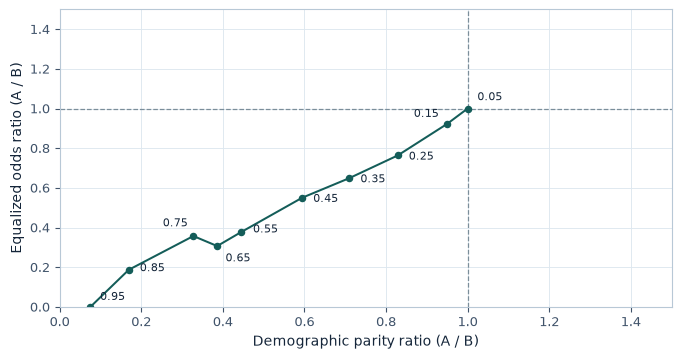

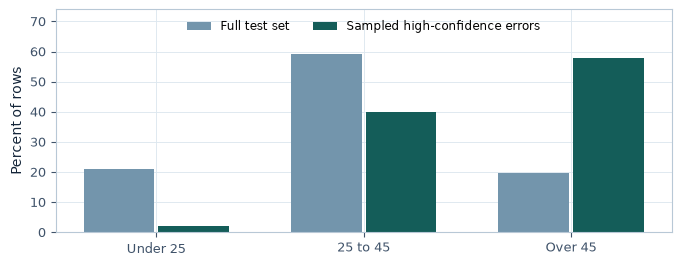

In [7]:
def chart_style(ax):
    ax.set_axisbelow(True)
    ax.grid(color='#dde7ef', linewidth=.65)
    for spine in ax.spines.values():
        spine.set_color('#b8c8d6')
    ax.tick_params(colors='#40536a', labelsize=9)
    ax.xaxis.label.set_color('#15263a')
    ax.yaxis.label.set_color('#15263a')


plot_points = fairness.dropna(subset=['DP', 'EO'])
fig_fairness, ax = plt.subplots(figsize=(6.7, 3.48), layout='constrained')
chart_style(ax)
ax.axhline(1, color='#7b8e9a', linestyle='--', linewidth=.9)
ax.axvline(1, color='#7b8e9a', linestyle='--', linewidth=.9)
ax.plot(plot_points['DP'], plot_points['EO'], color='#145d59', marker='o', linewidth=1.45, markersize=4.4)
label_offsets = {0.05: (7, 6), 0.15: (-24, 5), 0.25: (8, -3), 0.35: (8, -3),
                 0.45: (8, -3), 0.55: (9, 0), 0.65: (6, -11), 0.75: (-22, 7),
                 0.85: (8, -1), 0.95: (7, 5)}
for threshold, row in plot_points.iterrows():
    ax.annotate(f'{threshold:.2f}', (row['DP'], row['EO']), xytext=label_offsets[threshold],
                textcoords='offset points', color='#15263a', fontsize=8)
ax.set(xlim=(0, 1.5), ylim=(0, 1.5), xlabel='Demographic parity ratio (A / B)',
       ylabel='Equalized odds ratio (A / B)')

age_categories = ['Age <25', 'Age 25-45', 'Age >45']
fig_profile, ax = plt.subplots(figsize=(6.7, 2.55), layout='constrained')
chart_style(ax)
positions = np.arange(len(age_categories))
ax.bar(positions - .18, profile.loc[age_categories, 'Percent test'], width=.34,
       color='#7395ac', label='Full test set')
ax.bar(positions + .18, profile.loc[age_categories, 'Percent sample'], width=.34,
       color='#145d59', label='Sampled high-confidence errors')
ax.set(xticks=positions, xticklabels=['Under 25', '25 to 45', 'Over 45'], ylabel='Percent of rows', ylim=(0, 74))
ax.legend(loc='upper center', ncols=2, frameon=False, fontsize=8.5)

lo, hi, demonstration = .65, .75, .55
dp_gain = 100 * (fairness.loc[lo, 'DP'] / fairness.loc[hi, 'DP'] - 1)
eo_loss = 100 * (1 - fairness.loc[lo, 'EO'] / fairness.loc[hi, 'EO'])
cost = eo_loss / dp_gain
changes = group_rates.loc[lo, ['FP', 'TP']] - group_rates.loc[hi, ['FP', 'TP']]
changes['New flags'] = changes.sum(axis=1)
scenario = pd.DataFrame({'Group': [group_a, group_b], 'Illustrative probability': [.69, .71],
                         'Illustrative observed label': [1, 0]})
for limit in [hi, lo]:
    scenario[f'Flag at {limit:.2f}'] = scenario['Illustrative probability'].ge(limit).astype('int')
subset_detail = subset.groupby('error').agg(n=('age', 'size'), mean_age=('age', 'mean'),
    over45=('age', lambda ages: ages.gt(45).sum()), mean_priors=('priors_count', 'mean'),
    mean_probability=('probability', 'mean'))
sex_counts = data['sex'].value_counts()
odds_ratios = np.exp(subgroup.loc['priors_count', ['Pooled', 'Female', 'Male']].astype(float))
female_slope_increase = 100 * (subgroup.loc['priors_count', 'Female'] / subgroup.loc['priors_count', 'Male'] - 1)
most_frequent_label_accuracy = target.loc[test].value_counts(normalize=True).max()
print(f'Model A high={linear_flag.sum()}, Model B high={logistic_flag.sum()}, '
      f'OLS predicted range [{score.min():.4f}, {score.max():.4f}], '
      f'test majority-class accuracy={most_frequent_label_accuracy:.2%}')
print(logistic.params.round(5).to_string())
print(sex_counts.to_string())
print(odds_ratios.round(4).to_string())
print(f'Female prior slope relative increase: {female_slope_increase:.2f}%')
print(subset_detail.round(4).to_string())
print('Median age:', age_median)
print(f'{hi:.2f} to {lo:.2f}: DP gain={dp_gain:.4f}%, EO loss={eo_loss:.4f}%, cost={cost:.4f}')
print(changes.to_string())
print(scenario.to_string(index=False))
if plt.get_backend().lower() != 'agg':
    plt.show()